# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if (PROJECT_DIR / "challenge").exists():
    PROJECT_DIR = PROJECT_DIR / "challenge"

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (RAW_DATA_DIR, PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
if not DATA_PATH.exists():
    alt_path = PROJECT_DIR / "data" / "wine.csv"
    if alt_path.exists():
        DATA_PATH = alt_path

# TODO 1: Carga el archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)
print(f"Dataset cargado exitosamente. Dimensiones: {df.shape}")
df.head()


Dataset cargado exitosamente. Dimensiones: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
# TODO 2: reporta forma, tipos, nulos, duplicados y distribución de target
print(f"Forma del dataset (filas, columnas): {df.shape}")
print(f"Columnas predictoras: {df.shape[1] - 1}")
print("Número total de duplicados:", df.duplicated().sum())
print("Total de valores nulos (NaN):", int(df.isna().sum().sum()))

print("\nDistribución de la variable target:")
display(df["target"].value_counts().rename(index={0: "Clase 0", 1: "Clase 1", 2: "Clase 2"}))

profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "mean": df.mean(numeric_only=True).round(3),
    "std": df.std(numeric_only=True).round(3),
    "max": df.max(numeric_only=True),
})
display(profile)


Forma del dataset (filas, columnas): (178, 14)
Columnas predictoras: 13
Número total de duplicados: 0
Total de valores nulos (NaN): 0

Distribución de la variable target:


target
Clase 1    71
Clase 0    59
Clase 2    48
Name: count, dtype: int64

,dtype,missing,unique,min,mean,std,max
alcohol,float64,0,126,11.03,13.001,0.812,14.83
malic_acid,float64,0,133,0.74,2.336,1.117,5.80
ash,float64,0,79,1.36,2.367,0.274,3.23
alcalinity_of_ash,float64,0,63,10.60,19.495,3.340,30.00
magnesium,float64,0,53,70.00,99.742,14.282,162.00
total_phenols,float64,0,97,0.98,2.295,0.626,3.88
flavanoids,float64,0,132,0.34,2.029,0.999,5.08
nonflavanoid_phenols,float64,0,39,0.13,0.362,0.124,0.66
proanthocyanins,float64,0,101,0.41,1.591,0.572,3.58
color_intensity,float64,0,132,1.28,5.058,2.318,13.00


**Conclusión de calidad:**

1. **Estructura y Tipos:** El conjunto de datos consta de 178 filas y 14 columnas. Todas las 13 variables predictoras son continuas de tipo numérico (`float64`), y la variable objetivo `target` es discreta entera (`int64`), codificando 3 clases de vino (0, 1 y 2).
2. **Completitud y Duplicados:** No existen datos faltantes (`0` nulos en todas las columnas) ni registros duplicados (`0` duplicados). La calidad de la información a nivel de completitud e integridad es óptima.
3. **Distribución del Target:** Las clases presentan un desbalance moderado: la Clase 1 tiene 71 instancias (39.89%), la Clase 0 tiene 59 instancias (33.15%) y la Clase 2 tiene 48 instancias (26.97%). Debido a esta asimetría, es indispensable emplear partición estratificada (`stratify=df["target"]`) para mantener las proporciones exactas en train y test.
4. **Heterogeneidad de Escalas:** Se evidencia una enorme diferencia en los órdenes de magnitud de las variables. Por ejemplo, `nonflavanoid_phenols` varía en un rango estrecho $[0.13, 0.66]$, mientras que `proline` oscila entre $278$ y $1680$ (con desviación estándar de $\approx 315$). Modelos basados en distancias (KNN) o en optimización con regularización (Regresión Logística) requerirán obligatoriamente estandarización dentro del pipeline.
5. **Decisión:** Se conserva la totalidad de los datos sin remover registros ni variables en esta fase, procediendo a un split estratificado 80/20 protegiendo rigurosamente el conjunto de prueba de cualquier fuga de información.


## 2. Split train/test

In [5]:
# TODO 3: crea train_df (80 %) y test_df (20 %)
# Requisitos: stratify=df["target"] y random_state=RANDOM_STATE
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

print(f"Train set: {train_df.shape[0]} muestras ({train_df.shape[0]/len(df)*100:.1f}%)")
print(f"Test set:  {test_df.shape[0]} muestras ({test_df.shape[0]/len(df)*100:.1f}%)")
print("\nDistribución porcentual de clases:")
split_dist = pd.DataFrame({
    "Original (%)": (df["target"].value_counts(normalize=True) * 100).round(2),
    "Train (%)": (train_df["target"].value_counts(normalize=True) * 100).round(2),
    "Test (%)": (test_df["target"].value_counts(normalize=True) * 100).round(2),
})
display(split_dist)


Train set: 142 muestras (79.8%)
Test set:  36 muestras (20.2%)

Distribución porcentual de clases:


,Original (%),Train (%),Test (%)
target,,,
1,39.89,40.14,38.89
0,33.15,33.10,33.33
2,26.97,26.76,27.78


In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

/var/folders/1n/6pnqswwx6djfsb385t50h4lw0000gn/T/ipykernel_86641/3898059738.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x="target", y="flavanoids", ax=axes[0, 1], palette=colors)


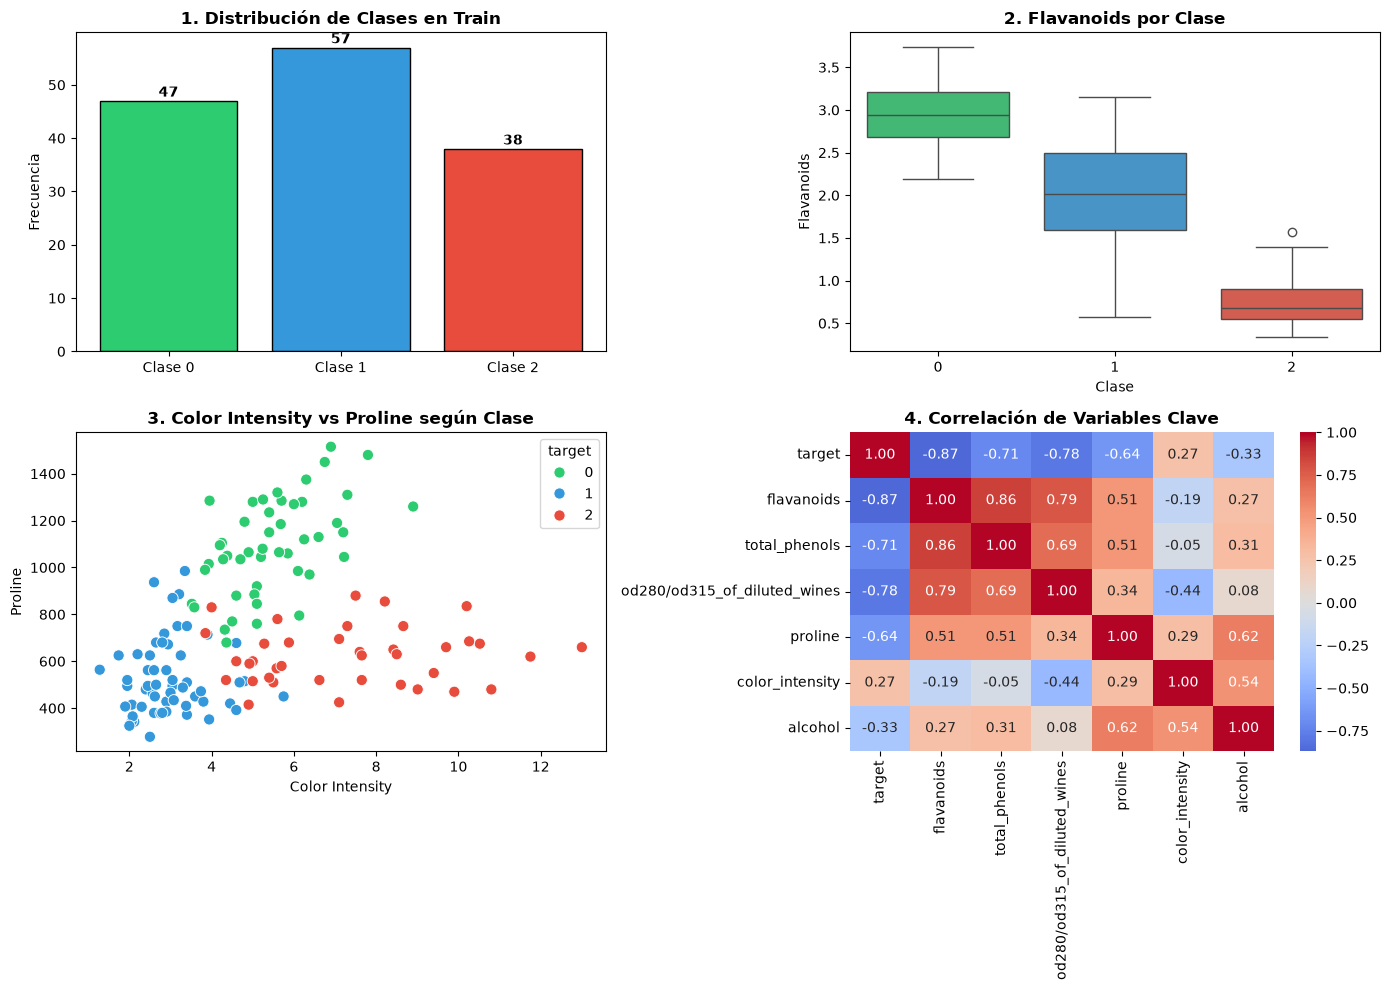

In [7]:
# TODO 4: crea al menos tres visualizaciones usando solamente train_df
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = ["#2ecc71", "#3498db", "#e74c3c"]

# 1. Distribución de clases en train
target_counts = train_df["target"].value_counts().sort_index()
axes[0, 0].bar([f"Clase {i}" for i in target_counts.index], target_counts.values, color=colors, edgecolor="black")
axes[0, 0].set_title("1. Distribución de Clases en Train", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("Frecuencia")
for i, v in enumerate(target_counts.values):
    axes[0, 0].text(i, v + 0.8, str(v), ha="center", fontweight="bold")

# 2. Boxplot de flavanoids por clase (fuerte poder discriminante)
sns.boxplot(data=train_df, x="target", y="flavanoids", ax=axes[0, 1], palette=colors)
axes[0, 1].set_title("2. Flavanoids por Clase", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Clase")
axes[0, 1].set_ylabel("Flavanoids")

# 3. Dispersión Proline vs Color Intensity
sns.scatterplot(
    data=train_df,
    x="color_intensity",
    y="proline",
    hue="target",
    palette=colors,
    s=65,
    ax=axes[1, 0],
)
axes[1, 0].set_title("3. Color Intensity vs Proline según Clase", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Color Intensity")
axes[1, 0].set_ylabel("Proline")

# 4. Matriz de correlación de variables clave con la clase
key_cols = ["target", "flavanoids", "total_phenols", "od280/od315_of_diluted_wines", "proline", "color_intensity", "alcohol"]
sns.heatmap(train_df[key_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 1], cbar=True)
axes[1, 1].set_title("4. Correlación de Variables Clave", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()


**Hallazgos:**

1. **Variables altamente discriminantes:** Las variables químicas `flavanoids`, `proline` y `color_intensity` presentan una fuerte capacidad para diferenciar las tres clases de vino. La Clase 0 posee altos niveles de `proline` y `flavanoids`; la Clase 1 tiene moderada o baja `color_intensity` con niveles medios de `flavanoids`; y la Clase 2 se concentra en una región con alta `color_intensity` y muy bajos `flavanoids`. Esta clara separación geométrica facilita que modelos lineales y basados en árboles encuentren límites de decisión muy certeros.
2. **Fuerte multicolinealidad entre compuestos fenólicos:** Existe una correlación positiva sustancial ($r \approx 0.86$) entre `flavanoids` y `total_phenols`, al igual que con `od280/od315_of_diluted_wines` ($r \approx 0.77$). Aunque los árboles de decisión son inmunes a variables correlacionadas, en la Regresión Logística esto puede provocar inestabilidad en los coeficientes, justificando la incorporación de regularización $L_2$ (Ridge) durante el ajuste de hiperparámetros.
3. **Disparidad crítica de escalas numéricas:** El rango de `proline` (con valores de hasta 1680 y media $\approx 740$) supera por órdenes de magnitud a características como `nonflavanoid_phenols` (valores menores a 0.7) o `alcohol` ($11-15$). En algoritmos basados en distancias (como KNN) o en optimizadores de descenso de gradiente, la falta de normalización provocaría que `proline` domine artificialmente toda la función de costo. Por tanto, es mandatorio incorporar un `StandardScaler` dentro de los pipelines respectivos.


## 4. Persistencia de datos y contrato

In [8]:
# TODO 5: reinicia los índices y guarda train.csv y test.csv sin el índice
# TODO 5: crea data_contract.json con target, features, random_state y test_size
train_df_clean = train_df.reset_index(drop=True)
test_df_clean = test_df.reset_index(drop=True)

train_df_clean.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df_clean.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

feature_columns = [col for col in df.columns if col != "target"]
contract = {
    "dataset": "Wine Recognition Dataset",
    "target": "target",
    "target_names": ["class_0", "class_1", "class_2"],
    "features": feature_columns,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "train_samples": len(train_df_clean),
    "test_samples": len(test_df_clean),
}

(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)

print(f"Archivos y contrato guardados exitosamente:")
print(f"- {PROCESSED_DATA_DIR / 'train.csv'} ({train_df_clean.shape})")
print(f"- {PROCESSED_DATA_DIR / 'test.csv'} ({test_df_clean.shape})")
print(f"- {ARTIFACTS_DIR / 'data_contract.json'}")


Archivos y contrato guardados exitosamente:
- /Users/frank/Downloads/EAFIT-IA si3003-artificial-intelligence main notebooks-lecture6/challenge/data/processed/train.csv ((142, 14))
- /Users/frank/Downloads/EAFIT-IA si3003-artificial-intelligence main notebooks-lecture6/challenge/data/processed/test.csv ((36, 14))
- /Users/frank/Downloads/EAFIT-IA si3003-artificial-intelligence main notebooks-lecture6/challenge/artifacts/data_contract.json


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.
